In [1]:
# ==============================================================================
# PREPARACAO E CODIFICACAO DA BASE PARA CLUSTERIZACAO (NHIS 2025)
# ==============================================================================
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

ID_DOMICILIO = "ID_DOMICILIO"
PESO_AMOSTRAL = "PESO_AMOSTRAL"
SEXO = "SEXO"
IDADE = "IDADE"
CLASSIFICACAO_URBANO_RURAL = "CLASSIFICACAO_URBANO_RURAL"
REGIAO_GEOGRAFICA = "REGIAO_GEOGRAFICA"
ESTADO_CIVIL_DECLARADO = "ESTADO_CIVIL_DECLARADO"
ESTADO_CIVIL = "ESTADO_CIVIL"
STATUS_PARENTAL = "STATUS_PARENTAL"
SEXO_CONJUGE = "SEXO_CONJUGE"
SEPARACAO_LEGAL_CONJUGAL = "SEPARACAO_LEGAL_CONJUGAL"
COJUGE_TRABALHA = "COJUGE_TRABALHA"
FLG_IDOSO_FAMILIA = "FLG_IDOSO_FAMILIA"
QTD_ADULTOS_FAMILIA = "QTD_ADULTOS_FAMILIA"
QTD_CRIANÇAS_FAMILIA = "QTD_CRIANÇAS_FAMILIA"
ESCOLARIDADE_MAXIMA_FAMILIA = "ESCOLARIDADE_MAXIMA_FAMILIA"
TEMPO_MORADIA_ANOS = "TEMPO_MORADIA_ANOS"
TIPO_POSSE_IMOVEL = "TIPO_POSSE_IMOVEL"
SUPORTE_SOCIAL = "SUPORTE_SOCIAL"
DEFICIENTE = "DEFICIENTE"
HISTORICO_ASMA = "HISTORICO_ASMA"
ASMA_ATIVA_ATUALMENTE = "ASMA_ATIVA_ATUALMENTE"
FREQUENCIA_FALHA_MEMORIA = "FREQUENCIA_FALHA_MEMORIA"
TIPO_DIFICULDADE_COGNITIVA = "TIPO_DIFICULDADE_COGNITIVA"
QTD_DIFICULDADE_COGNITIVA = "QTD_DIFICULDADE_COGNITIVA"
HISTORICO_TRANSTORNO_ANSIEDADE = "HISTORICO_TRANSTORNO_ANSIEDADE"
MED_ANSIEDADE = "MED_ANSIEDADE"
FREQ_ANSIEDADE = "FREQ_ANSIEDADE"
INTENSIDADE_ANSIEDADE = "INTENSIDADE_ANSIEDADE"
FREQ_ANSIEDADE_2SEM = "FREQ_ANSIEDADE_2SEM"
FREQ_PREOCUPACAO_INCONTROLAVEL_2SEM = "FREQ_PREOCUPACAO_INCONTROLAVEL_2SEM"
FREQ_PREOCUPACAO_DESNECESSARIA_2SEM = "FREQ_PREOCUPACAO_DESNECESSARIA_2SEM"
FREQ_DIFICULDADE_DESCANSAR_2SEM = "FREQ_DIFICULDADE_DESCANSAR_2SEM"
FREQ_AGITACAO_INQUIETA = "FREQ_AGITACAO_INQUIETA"
FREQ_IRRITABILIDADE_2SEM = "FREQ_IRRITABILIDADE_2SEM"
FREQ_MEDO_2SEM = "FREQ_MEDO_2SEM"
SEVERIDADE_ANSIEDADE = "SEVERIDADE_ANSIEDADE"
HISTORICO_DEPRESSAO = "HISTORICO_DEPRESSAO"
REMEDIO_DEPRESSAO = "REMEDIO_DEPRESSAO"
FREQ_DEPRESSAO = "FREQ_DEPRESSAO"
INTENSIDADE_DEPRESSAO = "INTENSIDADE_DEPRESSAO"
FREQ_PERDA_INTERESSE_2SEM = "FREQ_PERDA_INTERESSE_2SEM"
FREQ_SENTIU_DEPRIMIDO_2SEM = "FREQ_SENTIU_DEPRIMIDO_2SEM"
FREQ_DIFICULDADE_DORMIR_2SEM = "FREQ_DIFICULDADE_DORMIR_2SEM"
FREQ_CANSASO_2SEM = "FREQ_CANSASO_2SEM"
FREQ_HIPOREXIA_COMPULSAO_ALIMENTAR_2SEM = "FREQ_HIPOREXIA_COMPULSAO_ALIMENTAR_2SEM"
FREQ_AUTOAVALIACAO_NEGTIVA_2SEM = "FREQ_AUTOAVALIACAO_NEGTIVA_2SEM"
FREQ_DIFICULDADE_CONCENTRACAO_2SEM = "FREQ_DIFICULDADE_CONCENTRACAO_2SEM"
MODIFICACAO_VELOCIDADE_FALA = "MODIFICACAO_VELOCIDADE_FALA"
SEVERIDADE_DEPRESSAO_PHQ = "SEVERIDADE_DEPRESSAO_PHQ"
NATURAL_ESTADOS_UNIDOS = "NATURAL_ESTADOS_UNIDOS"
AUTOAVALIACAO_SAUDE_GERAL = "AUTOAVALIACAO_SAUDE_GERAL"
CATEGORIA_IMC = "CATEGORIA_IMC"
HISTORICO_COLESTEROL = "HISTORICO_COLESTEROL"
HISTORICO_DIABETES = "HISTORICO_DIABETES"
HISTORICO_HIPERTENSAO = "HISTORICO_HIPERTENSAO"
HISTORICO_ARTRITE = "HISTORICO_ARTRITE"
CONCUSSAO_SINTOMAS_POS_TRAUMA = "CONCUSSAO_SINTOMAS_POS_TRAUMA"
DIFICULDADE_LOCOMOCAO = "DIFICULDADE_LOCOMOCAO"
LIMITACAO_TRABALHO_POR_SAUDE = "LIMITACAO_TRABALHO_POR_SAUDE"
DOR_CRONICA = "DOR_CRONICA"
TEVE_CANCER = "TEVE_CANCER"
ULTIMA_VISITA_MEDICO = "ULTIMA_VISITA_MEDICO"
CATEGORIA_RAZAO_POBREZA = "CATEGORIA_RAZAO_POBREZA"
RAZAO_RENDA_POBREZA = "RAZAO_RENDA_POBREZA"
RENDA_INVESTIMENTOS = "RENDA_INVESTIMENTOS"
VISITAS_PRONTO_ATENDIMENTO_12M = "VISITAS_PRONTO_ATENDIMENTO_12M"
VISITAS_EMERGENCIA_HOSPITALAR_12M = "VISITAS_EMERGENCIA_HOSPITALAR_12M"
VISITAS_EXAME_VISTA_12M = "VISITAS_EXAME_VISTA_12M"
PLANO_PUBLICO = "PLANO_PUBLICO"
PLANO_PRIVADO = "PLANO_PRIVADO"
ESTRESSE_FINANCEIRO_MEDICO = "ESTRESSE_FINANCEIRO_MEDICO"
JA_FUMANTE = "JA_FUMANTE"
FREQ_SOLITARIO = "FREQ_SOLITARIO"
FREQ_SOLITARIO_CABECALHO_LEGADO = "FREQ_SOLITARIO"






# 2. Leitura otimizada direto do CSV
df_hac = pd.read_csv(Path("../1-limpeza/dados/dados_limpos") / "adult25_limpo.csv", low_memory=False)

assert df_hac.shape[1] == 73, f"Esperados 73 atributos selecionados, encontrados {df_hac.shape[1]}."

print(f"\nBase selecionada importada com sucesso!")
print(f"Dimensoes da base original: {df_hac.shape[0]:,} participantes e {df_hac.shape[1]} atributos.")

colunas_metadados = [ID_DOMICILIO, PESO_AMOSTRAL]
df_hac = df_hac.drop(columns=colunas_metadados)
print(f"Atributos apos remover metadados: {df_hac.shape[1]}")



Base selecionada importada com sucesso!
Dimensoes da base original: 24,215 participantes e 73 atributos.
Atributos apos remover metadados: 71


In [2]:
df_hac.head()

,IDADE,SEXO,CLASSIFICACAO_URBANO_RURAL,REGIAO_GEOGRAFICA,ESTADO_CIVIL_DECLARADO,ESTADO_CIVIL,STATUS_PARENTAL,SEXO_CONJUGE,SEPARACAO_LEGAL_CONJUGAL,COJUGE_TRABALHA,...,FREQ_CANSASO_2SEM,FREQ_HIPOREXIA_COMPULSAO_ALIMENTAR_2SEM,FREQ_AUTOAVALIACAO_NEGTIVA_2SEM,FREQ_DIFICULDADE_CONCENTRACAO_2SEM,MODIFICACAO_VELOCIDADE_FALA,SEVERIDADE_DEPRESSAO_PHQ,FREQ_SOLITARIO,FREQUENCIA_FALHA_MEMORIA,TIPO_DIFICULDADE_COGNITIVA,QTD_DIFICULDADE_COGNITIVA
0,71,2,4,3,1,1,3,1,0,0,...,4,4,2,1,2,3,3,4,4,1
1,67,1,4,3,3,5,3,0,0,0,...,2,2,1,1,1,1,2,1,1,2
2,19,1,2,3,3,7,3,0,0,0,...,2,2,2,3,2,2,2,4,4,1
3,71,1,2,3,1,1,3,2,0,0,...,2,1,1,1,1,1,2,4,4,1
4,55,2,2,3,3,7,3,0,0,0,...,2,1,1,1,1,1,2,4,4,1


## Codificacao one-hot e preparacao dos atributos

As variaveis categoricas sao convertidas em colunas indicadoras one-hot. Cada categoria observada gera sua propria coluna, sem interpretar codigos desconhecidos ou nao aplicaveis como respostas validas.

`ID_DOMICILIO` e `PESO_AMOSTRAL` sao removidos e nao participam do calculo das distancias. As variaveis numericas sao padronizadas antes da clusterizacao.

In [3]:

colunas_numericas = [RAZAO_RENDA_POBREZA, IDADE]
colunas_categoricas = [
    coluna
    for coluna in df_hac.columns
    if coluna not in colunas_numericas
]

if df_hac.isna().any().any():
    colunas_com_ausencias = df_hac.columns[df_hac.isna().any()].tolist()
    raise ValueError(f"A base ainda contem valores nulos antes do one-hot encoding: {colunas_com_ausencias}")
if not colunas_categoricas:
    raise ValueError("Nenhuma variavel categorica foi identificada para codificacao.")

df_codificado = pd.get_dummies(
    df_hac,
    columns=colunas_categoricas,
    prefix=colunas_categoricas,
    prefix_sep="__",
    dtype=np.int8,
)


X_clusterizacao = df_codificado.copy()

from sklearn.preprocessing import StandardScaler
X_clusterizacao[colunas_numericas] = StandardScaler().fit_transform(
    X_clusterizacao[colunas_numericas]
)

assert X_clusterizacao.notna().all().all(), "A matriz de atributos contem valores nulos."
assert all(pd.api.types.is_numeric_dtype(tipo) for tipo in X_clusterizacao.dtypes), "A matriz contem atributos nao numericos."
assert np.isfinite(X_clusterizacao.to_numpy(dtype=np.float64)).all(), "A matriz contem valores infinitos."
assert not set(colunas_categoricas).intersection(X_clusterizacao.columns), "Uma coluna categorica original permaneceu sem codificacao."


for coluna in colunas_categoricas:
    colunas_indicadoras = [nome for nome in df_codificado.columns if nome.startswith(f"{coluna}__")]
    if not colunas_indicadoras:
        raise ValueError(f"Nenhuma coluna one-hot foi criada para {coluna}.")
    if not df_codificado[colunas_indicadoras].sum(axis=1).eq(1).all():
        raise ValueError(f"Cada registro deve ter exatamente uma categoria ativa em {coluna}.")

print(f"Variaveis categoricas codificadas: {len(colunas_categoricas)}")
print(f"Atributos na matriz para clusterizacao: {X_clusterizacao.shape[1]}")
print(f"Valores nulos na matriz: {int(X_clusterizacao.isna().sum().sum())}")
display(X_clusterizacao.head())

Variaveis categoricas codificadas: 69
Atributos na matriz para clusterizacao: 321
Valores nulos na matriz: 0


,IDADE,RAZAO_RENDA_POBREZA,SEXO__-1,SEXO__1,SEXO__2,CLASSIFICACAO_URBANO_RURAL__1,CLASSIFICACAO_URBANO_RURAL__2,CLASSIFICACAO_URBANO_RURAL__3,CLASSIFICACAO_URBANO_RURAL__4,REGIAO_GEOGRAFICA__1,...,TIPO_DIFICULDADE_COGNITIVA__-1,TIPO_DIFICULDADE_COGNITIVA__1,TIPO_DIFICULDADE_COGNITIVA__2,TIPO_DIFICULDADE_COGNITIVA__3,TIPO_DIFICULDADE_COGNITIVA__4,QTD_DIFICULDADE_COGNITIVA__-1,QTD_DIFICULDADE_COGNITIVA__1,QTD_DIFICULDADE_COGNITIVA__2,QTD_DIFICULDADE_COGNITIVA__3,QTD_DIFICULDADE_COGNITIVA__4
0,0.908759,-0.876563,0,0,1,0,0,0,1,0,...,0,0,0,0,1,0,1,0,0,0
1,0.696469,-0.001807,0,1,0,0,0,0,1,0,...,0,1,0,0,0,0,0,1,0,0
2,-1.851016,-1.323519,0,1,0,0,1,0,0,0,...,0,0,0,0,1,0,1,0,0,0
3,0.908759,0.636701,0,1,0,0,1,0,0,0,...,0,0,0,0,1,0,1,0,0,0
4,0.059597,0.183360,0,0,1,0,1,0,0,0,...,0,0,0,0,1,0,1,0,0,0


Observacoes no HAC: 24,215
Memoria estimada para as distancias: 2.18 GiB
Distancia de corte escolhida: 110.00


C:\Users\theus\AppData\Local\Temp\ipykernel_26380\795237000.py:39: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
C:\Users\theus\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


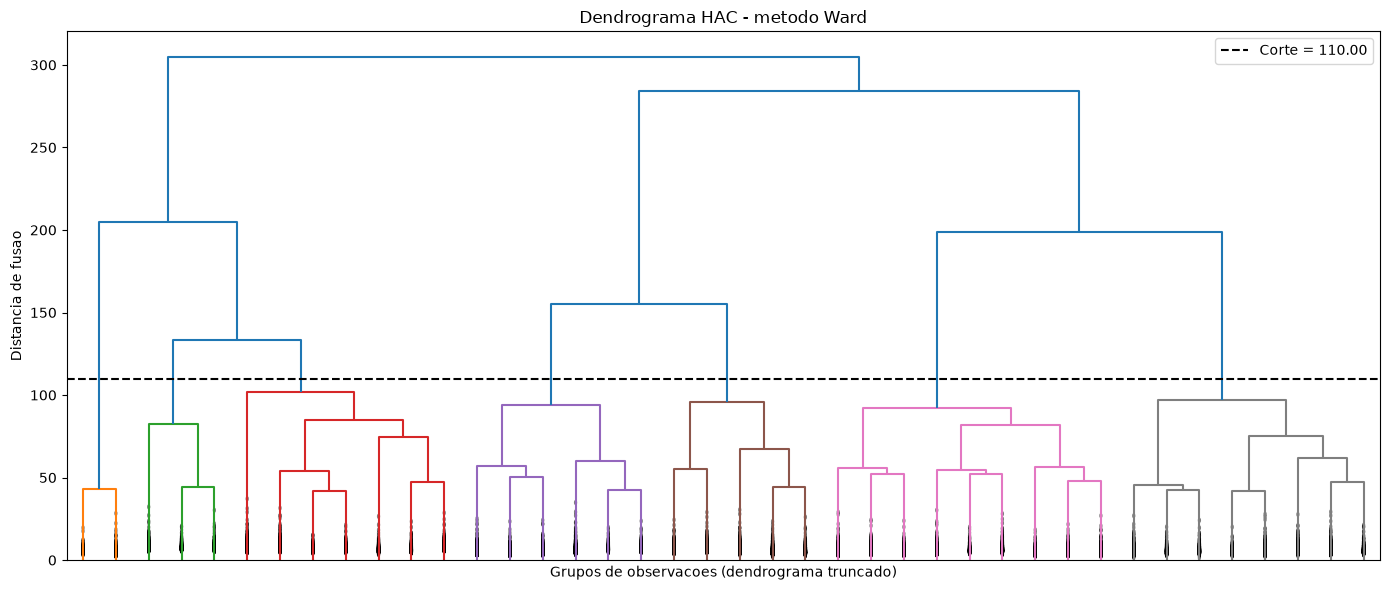

Numero de clusters no corte escolhido: 7


,quantidade
cluster_hac,
1,546
2,1481
3,3582
4,3651
5,4185
6,5559
7,5211


In [4]:
from scipy.cluster.hierarchy import fcluster

n_observacoes = len(X_clusterizacao)
memoria_distancias_gib = (
    n_observacoes * (n_observacoes - 1) // 2
    * np.dtype(np.float64).itemsize
    / 1024**3
)
print(f"Observacoes no HAC: {n_observacoes:,}")
print(f"Memoria estimada para as distancias: {memoria_distancias_gib:.2f} GiB")

Z_hac = linkage(
    X_clusterizacao.to_numpy(dtype=np.float64),
    method="ward",
    metric="euclidean",
)

alturas_fusoes_superiores = Z_hac[-5:, 2]
lacunas_fusoes = np.diff(alturas_fusoes_superiores)
indice_maior_lacuna = int(np.argmax(lacunas_fusoes))
distancia_corte = float(110)
print(f"Distancia de corte escolhida: {distancia_corte:.2f}")

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(
    Z_hac,
    truncate_mode="lastp",
    p=40,
    show_contracted=True,
    no_labels=True,
    color_threshold=distancia_corte,
    ax=ax,
)
ax.axhline(distancia_corte, color="black", linestyle="--", label=f"Corte = {distancia_corte:.2f}")
ax.set_title("Dendrograma HAC - metodo Ward")
ax.set_xlabel("Grupos de observacoes (dendrograma truncado)")
ax.set_ylabel("Distancia de fusao")
ax.legend()
fig.tight_layout()
plt.show()

labels_hac = fcluster(Z_hac, t=distancia_corte, criterion="distance")
df_hac_clusterizado = df_hac.copy()
df_hac_clusterizado["cluster_hac"] = labels_hac
n_clusters_hac = df_hac_clusterizado["cluster_hac"].nunique()
print(f"Numero de clusters no corte escolhido: {n_clusters_hac}")
display(
    df_hac_clusterizado["cluster_hac"]
    .value_counts()
    .sort_index()
    .rename("quantidade")
    .to_frame()
)

HAC forma uma hierarquia de fusoes por distancia. O corte horizontal no dendrograma determina quantos clusters resultam. A distancia de corte e escolhida pelo maior intervalo entre as cinco fusoes finais. A projecao PCA abaixo ajuda a visualizar os grupos em duas dimensoes, mas e apenas uma projecao dos atributos usados no HAC.

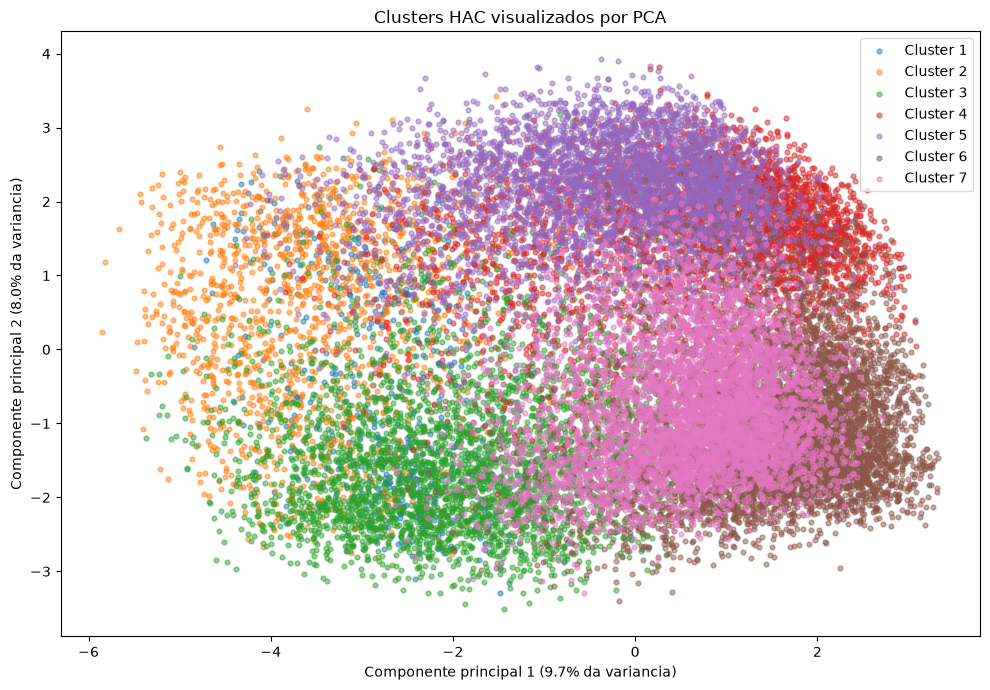

Matriz de atributos salva em: dados_clusterizacao\adult25_clusterizacao_onehot_2025.csv
Dados clusterizados salvos em: dados_clusterizacao\adult25_hac_clusterizados_2025.csv


In [5]:
pasta_saida_clusterizacao = Path("dados_clusterizacao")
pasta_saida_clusterizacao.mkdir(parents=True, exist_ok=True)

arquivo_atributos = pasta_saida_clusterizacao / "adult25_clusterizacao_onehot_2025.csv"
arquivo_clusters = pasta_saida_clusterizacao / "adult25_hac_clusterizados_2025.csv"
X_clusterizacao.to_csv(arquivo_atributos, index=False)
df_hac_clusterizado.to_csv(arquivo_clusters, index=False)

from sklearn.decomposition import PCA

pca = PCA(n_components=2, svd_solver="randomized", random_state=42)
projecao_pca = pca.fit_transform(X_clusterizacao)
fig, ax = plt.subplots(figsize=(10, 7))
for cluster in sorted(df_hac_clusterizado["cluster_hac"].unique()):
    mascara = df_hac_clusterizado["cluster_hac"].to_numpy() == cluster
    ax.scatter(
        projecao_pca[mascara, 0],
        projecao_pca[mascara, 1],
        s=12,
        alpha=0.5,
        label=f"Cluster {cluster}",
        rasterized=True,
    )
ax.set_title("Clusters HAC visualizados por PCA")
ax.set_xlabel(f"Componente principal 1 ({pca.explained_variance_ratio_[0]:.1%} da variancia)")
ax.set_ylabel(f"Componente principal 2 ({pca.explained_variance_ratio_[1]:.1%} da variancia)")
ax.legend()
fig.tight_layout()
plt.show()

print(f"Matriz de atributos salva em: {arquivo_atributos}")
print(f"Dados clusterizados salvos em: {arquivo_clusters}")

In [6]:
df_hac_clusterizado

,IDADE,SEXO,CLASSIFICACAO_URBANO_RURAL,REGIAO_GEOGRAFICA,ESTADO_CIVIL_DECLARADO,ESTADO_CIVIL,STATUS_PARENTAL,SEXO_CONJUGE,SEPARACAO_LEGAL_CONJUGAL,COJUGE_TRABALHA,...,FREQ_HIPOREXIA_COMPULSAO_ALIMENTAR_2SEM,FREQ_AUTOAVALIACAO_NEGTIVA_2SEM,FREQ_DIFICULDADE_CONCENTRACAO_2SEM,MODIFICACAO_VELOCIDADE_FALA,SEVERIDADE_DEPRESSAO_PHQ,FREQ_SOLITARIO,FREQUENCIA_FALHA_MEMORIA,TIPO_DIFICULDADE_COGNITIVA,QTD_DIFICULDADE_COGNITIVA,cluster_hac
0,71,2,4,3,1,1,3,1,0,0,...,4,2,1,2,3,3,4,4,1,2
1,67,1,4,3,3,5,3,0,0,0,...,2,1,1,1,1,2,1,1,2,5
2,19,1,2,3,3,7,3,0,0,0,...,2,2,3,2,2,2,4,4,1,3
3,71,1,2,3,1,1,3,2,0,0,...,1,1,1,1,1,2,4,4,1,4
4,55,2,2,3,3,7,3,0,0,0,...,1,1,1,1,1,2,4,4,1,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24210,53,2,3,4,1,1,3,1,0,1,...,1,1,1,1,1,1,4,4,1,6
24211,34,1,4,4,3,5,1,0,0,0,...,2,4,1,2,3,5,4,2,2,2
24212,68,1,4,4,3,4,3,0,0,0,...,1,1,1,1,1,1,1,1,2,5
24213,72,2,4,4,1,1,3,1,0,0,...,1,2,2,1,1,2,4,4,1,4


## Perfil e comparacao dos clusters

As variaveis categoricas do perfil sao referenciadas pelas constantes declaradas na primeira celula. O codigo `-1` aparece como `Não sei/indeterminado` nas tabelas. Para idade, `-1` e excluido das estatisticas numericas.

In [ ]:
tamanho_clusters = (
    df_hac_clusterizado.groupby("cluster_hac")
    .size()
    .rename("participantes")
    .to_frame()
)
tamanho_clusters["percentual"] = (
    100 * tamanho_clusters["participantes"] / len(df_hac_clusterizado)
).round(1)
display(tamanho_clusters)

df_perfil = df_hac_clusterizado.copy()
df_perfil["IDADE"] = df_perfil["IDADE"].where(df_perfil["IDADE"] >= 0)
perfil_numerico = df_perfil.groupby("cluster_hac").agg(
    idade_mediana=("IDADE", "median"),
    idade_q1=("IDADE", lambda valores: valores.quantile(0.25)),
    idade_q3=("IDADE", lambda valores: valores.quantile(0.75)),
    renda_pobreza_mediana=("RAZAO_RENDA_POBREZA", "median"),
    renda_pobreza_q1=("RAZAO_RENDA_POBREZA", lambda valores: valores.quantile(0.25)),
    renda_pobreza_q3=("RAZAO_RENDA_POBREZA", lambda valores: valores.quantile(0.75)),
)
display(perfil_numerico.round(2))

variaveis_categoricas_perfil = [
    SEVERIDADE_ANSIEDADE,
    SEVERIDADE_DEPRESSAO_PHQ,
    HISTORICO_TRANSTORNO_ANSIEDADE,
    HISTORICO_DEPRESSAO,
    FREQ_ANSIEDADE_2SEM,
    FREQ_SENTIU_DEPRIMIDO_2SEM,
    SUPORTE_SOCIAL,
    AUTOAVALIACAO_SAUDE_GERAL,
]

for variavel in variaveis_categoricas_perfil:
    distribuicao = pd.crosstab(
        df_hac_clusterizado["cluster_hac"],
        df_hac_clusterizado[variavel],
        normalize="index",
    ).mul(100).round(1)
    distribuicao = distribuicao.rename(
        columns={-1: "Não sei/indeterminado (-1)"}
    )
    distribuicao.columns.name = "codigo_resposta"
    print(f"{variavel} (% dentro de cada cluster)")
    display(distribuicao.apply(lambda coluna: coluna.map("{:.1f}%".format)))